# **Lab 9 - Morphological Operations (Solution)**

## **Task 1: Apply morphological operations to a new image**

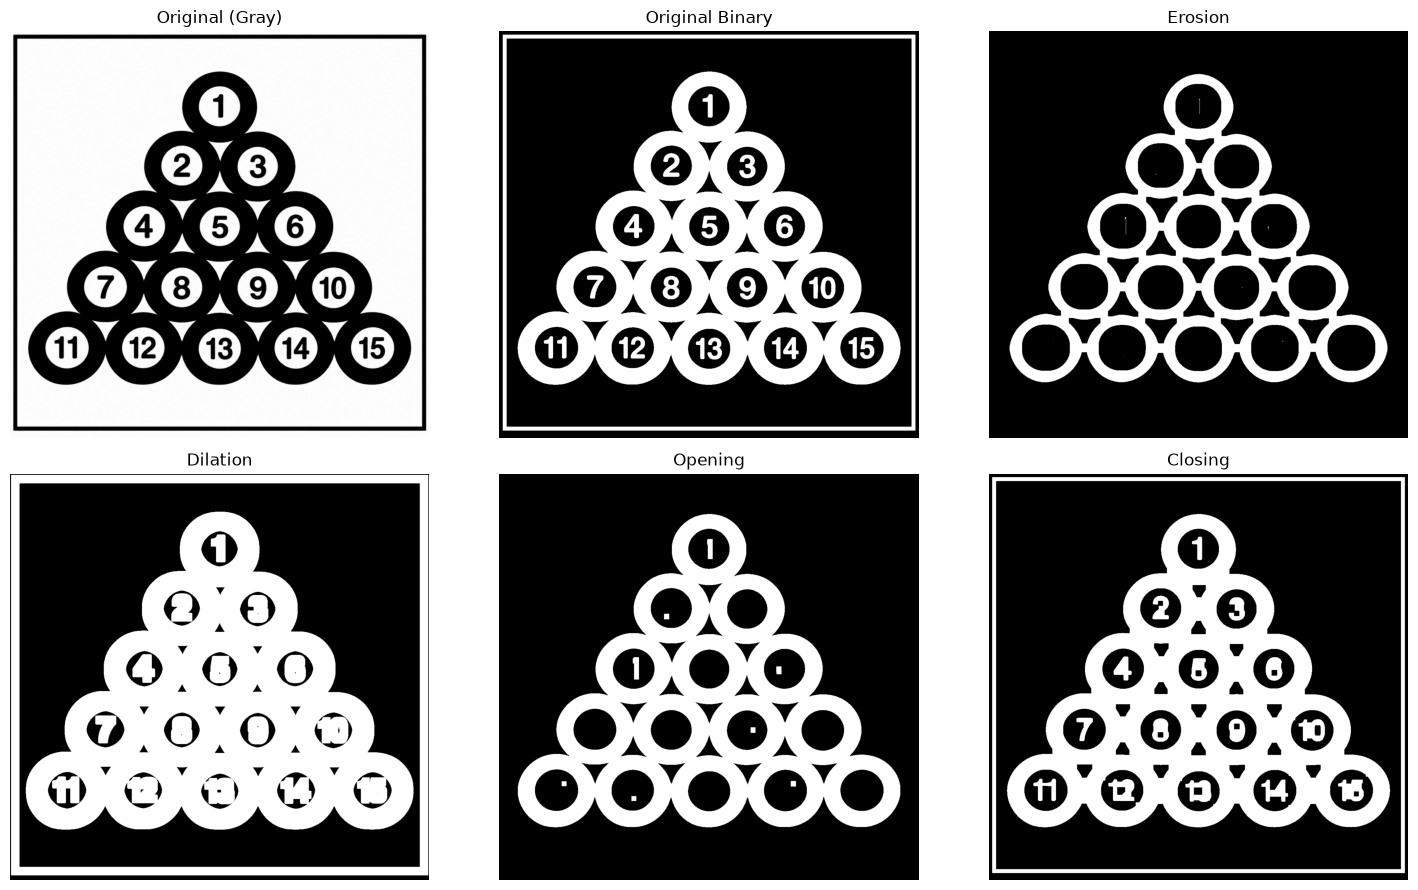

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = '../images/Balls.png'

# 1. Load image in grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize with Otsu (inverted so the balls become the white foreground)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Define a 15x15 square kernel (the image is large, so a small kernel barely changes it)
kernel = np.ones((15, 15), np.uint8)

# 4. Apply the four morphological operations
eroded  = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)   # dilate(erode(binary))
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)  # erode(dilate(binary))

# 5. Display the original image and the results of each operation
titles = ['Original (Gray)', 'Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [img, binary, eroded, dilated, opening, closing]

plt.figure(figsize=(15, 9))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

## **Task 2: Experiment with structuring elements**

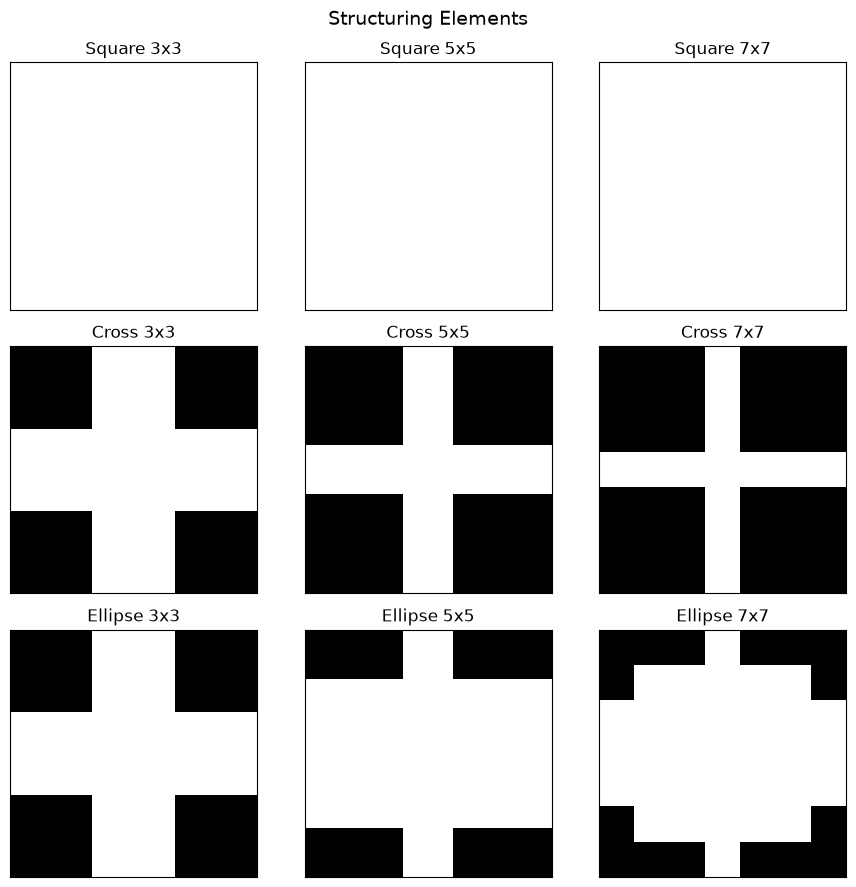

Ellipse 7x7 kernel:
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]


In [2]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

# Build every kernel: kernels[(shape_name, size)]
kernels = {(name, k): cv2.getStructuringElement(shape, (k, k))
           for name, shape in shapes.items() for k in sizes}

# Visualize the structuring elements themselves
plt.figure(figsize=(9, 9))
i = 1
for name in shapes:
    for k in sizes:
        plt.subplot(3, 3, i)
        plt.imshow(kernels[(name, k)], 'gray', vmin=0, vmax=1)
        plt.title(f'{name} {k}x{k}')
        plt.xticks([]), plt.yticks([])
        i += 1
plt.suptitle('Structuring Elements', fontsize=14)
plt.tight_layout()
plt.show()

print('Ellipse 7x7 kernel:')
print(kernels[('Ellipse', 7)])

### **Erosion with Different Structuring Elements**

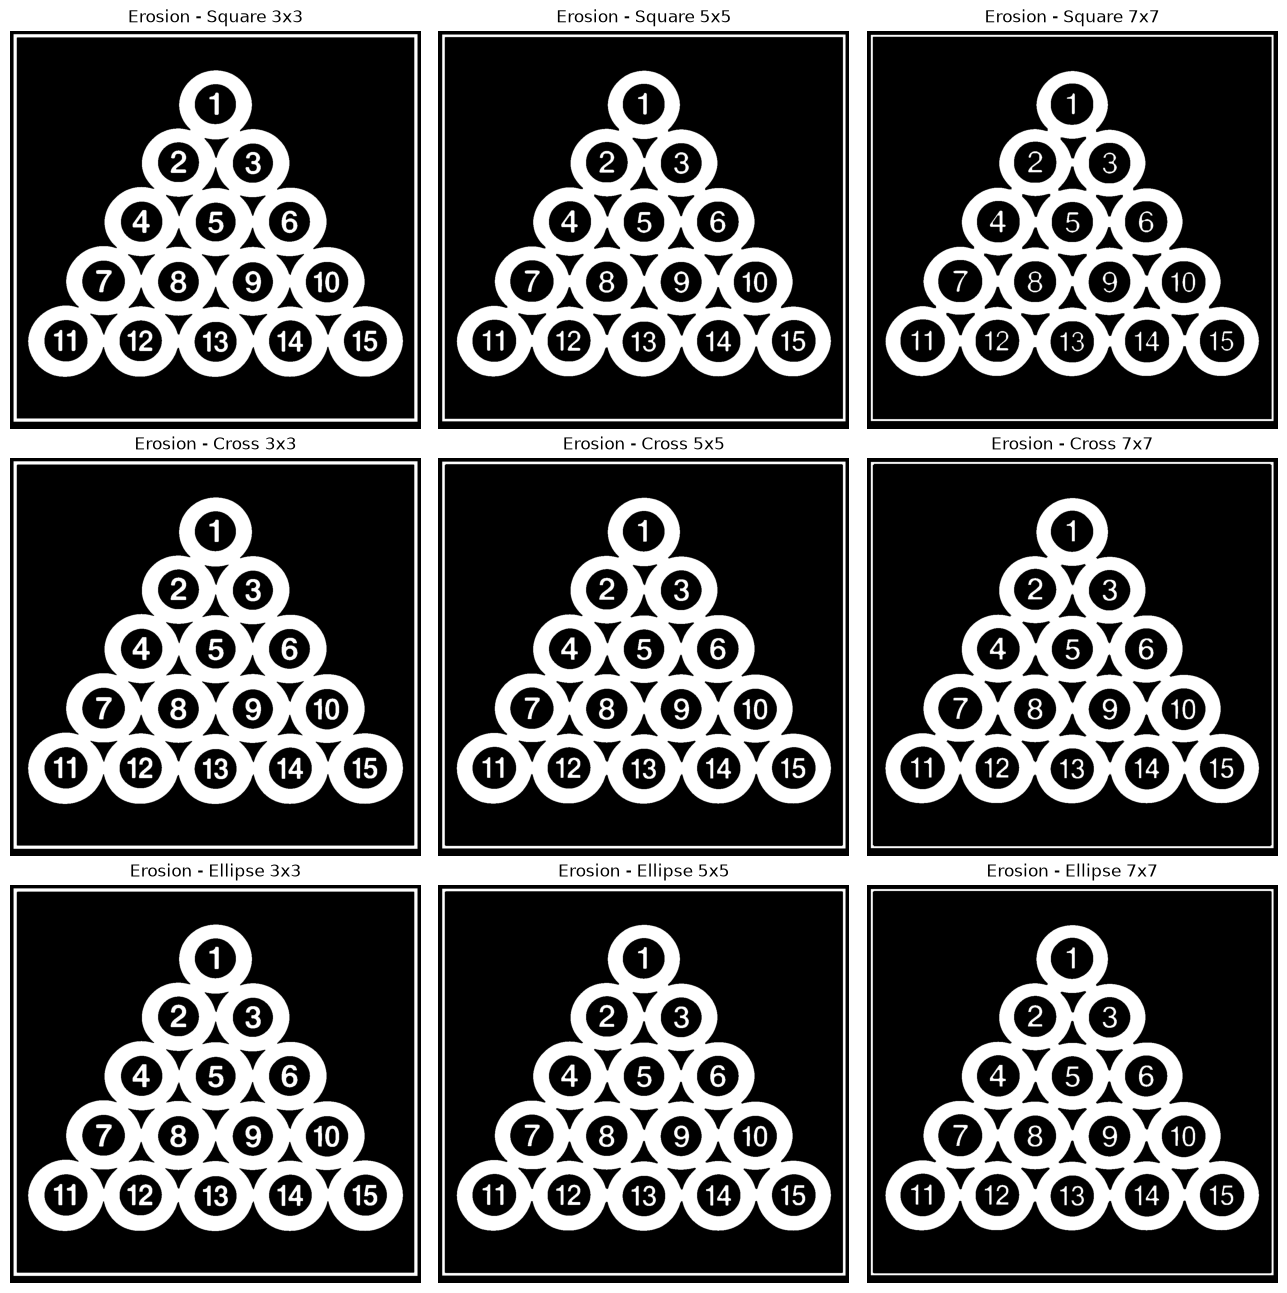

In [3]:
plt.figure(figsize=(13, 13))
i = 1
for name in shapes:
    for k in sizes:
        result = cv2.erode(binary, kernels[(name, k)], iterations=1)
        plt.subplot(3, 3, i)
        plt.imshow(result, 'gray')
        plt.title(f'Erosion - {name} {k}x{k}')
        plt.axis('off')
        i += 1
plt.tight_layout()
plt.show()

### **Dilation with Different Structuring Elements**

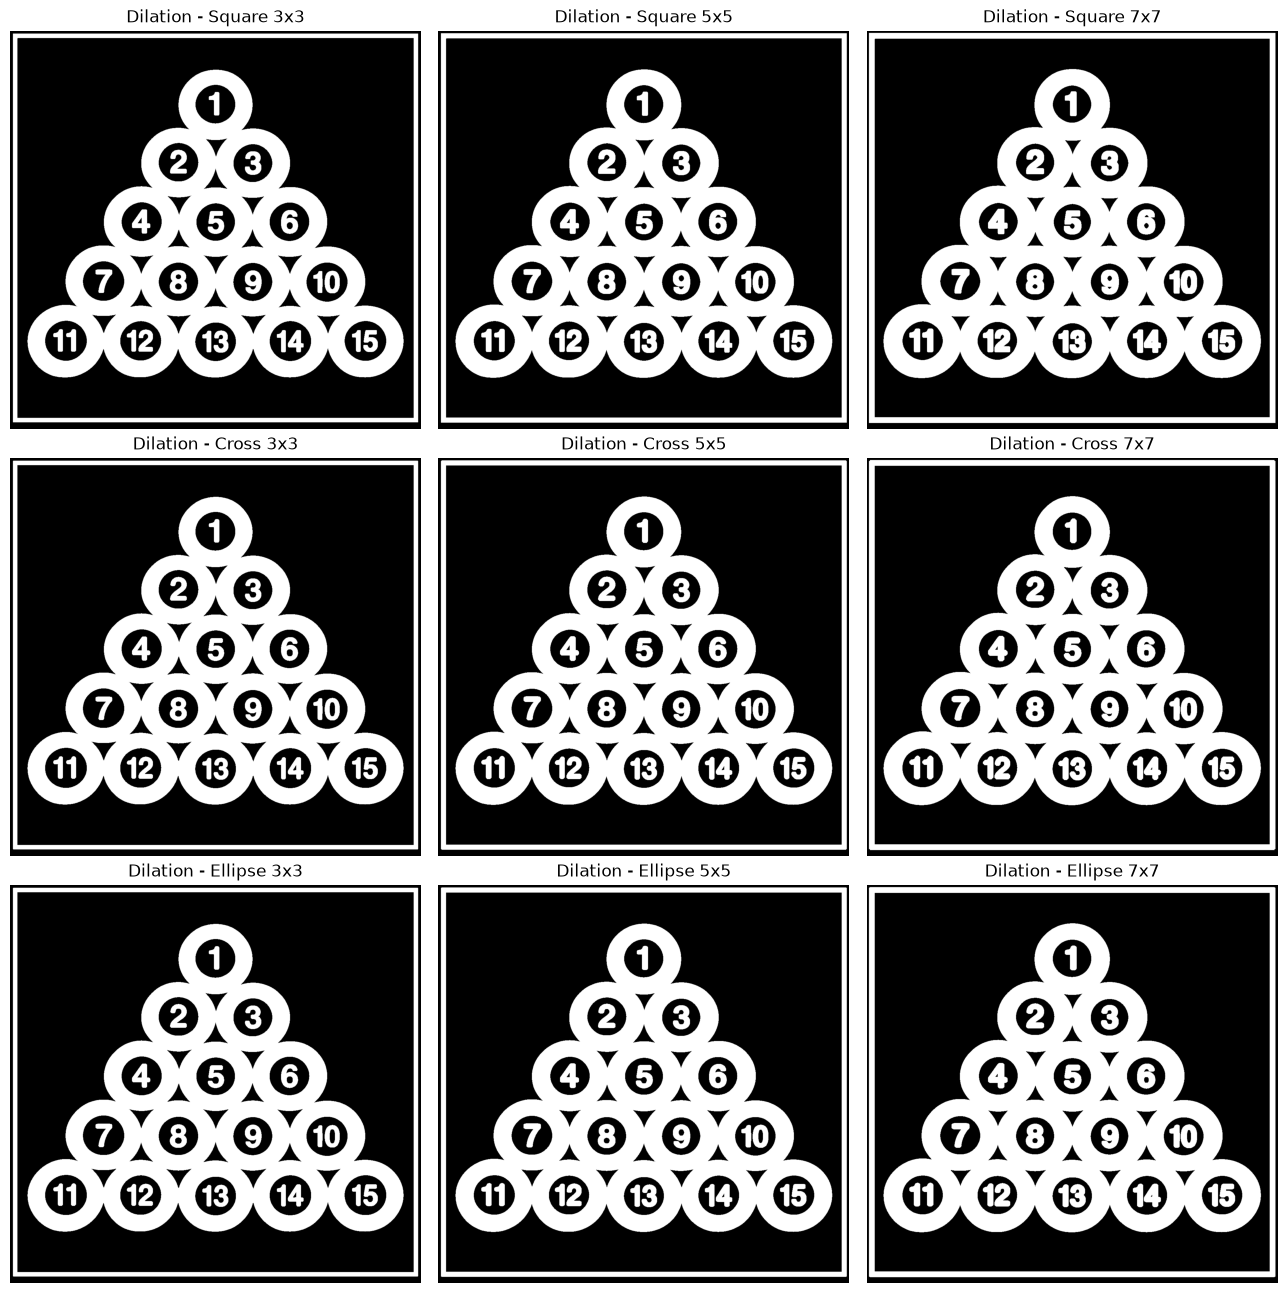

In [4]:
plt.figure(figsize=(13, 13))
i = 1
for name in shapes:
    for k in sizes:
        result = cv2.dilate(binary, kernels[(name, k)], iterations=1)
        plt.subplot(3, 3, i)
        plt.imshow(result, 'gray')
        plt.title(f'Dilation - {name} {k}x{k}')
        plt.axis('off')
        i += 1
plt.tight_layout()
plt.show()

### **Comparing the Results**

In [5]:
# Compare by counting white (foreground) pixels for every shape/size combination
original_count = cv2.countNonZero(binary)
print(f'Original binary image: {original_count} white pixels\n')

print(f"{'Kernel':<14}{'Ones in SE':>11}{'Erosion':>10}{'Dilation':>10}")
print('-' * 45)
for k in sizes:
    for name in shapes:
        se = kernels[(name, k)]
        er = cv2.countNonZero(cv2.erode(binary, se))
        di = cv2.countNonZero(cv2.dilate(binary, se))
        print(f"{name + ' ' + str(k) + 'x' + str(k):<14}{int(se.sum()):>11}{er:>10}{di:>10}")
    print()

Original binary image: 500374 white pixels

Kernel         Ones in SE   Erosion  Dilation
---------------------------------------------
Square 3x3              9    466395    534094
Cross 3x3               5    473108    527560
Ellipse 3x3             5    473108    527560

Square 5x5             25    432293    567126
Cross 5x5               9    445935    554380
Ellipse 5x5            17    440791    559214

Square 7x7             49    398085    599496
Cross 7x7              13    418852    580813
Ellipse 7x7            33    413345    585692



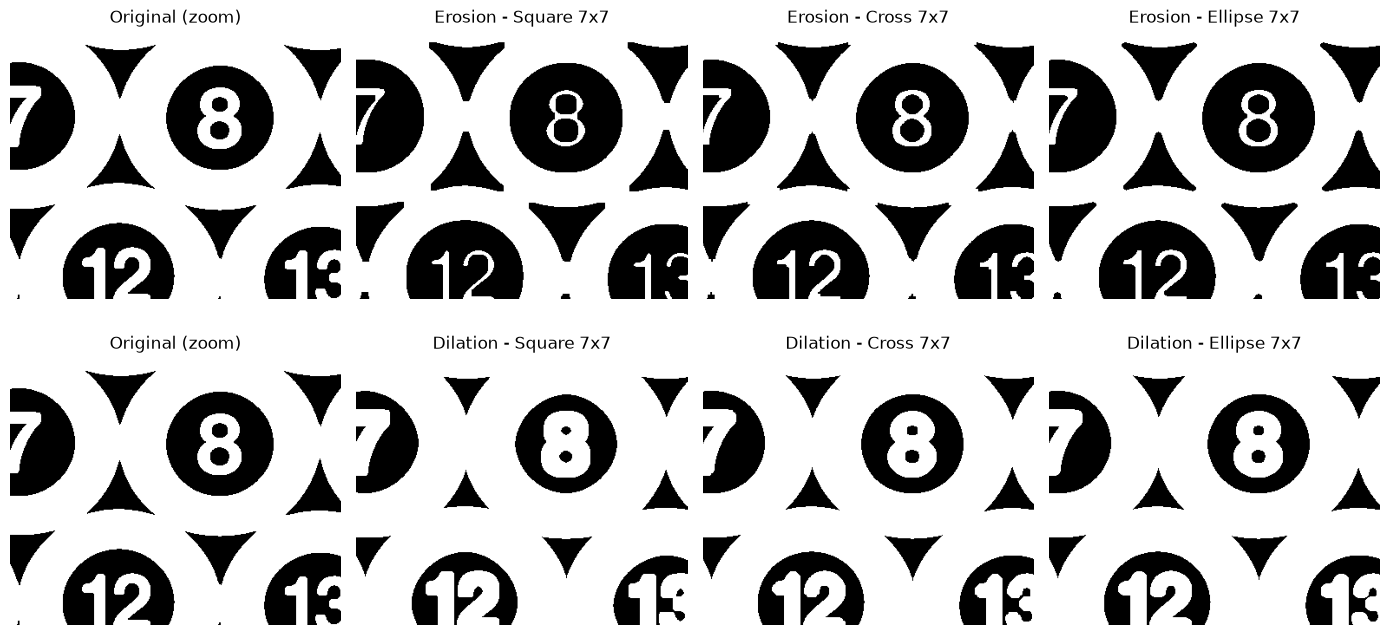

In [6]:
# Close-up of balls 7, 8, 12, 13 to show how the SHAPE of the kernel changes the result
# (same size 7x7 for all three shapes so only the shape differs)
# Crop is given as a fraction of the image size so it works at any resolution
h, w = binary.shape
y0, y1, x0, x1 = int(0.55 * h), int(0.80 * h), int(0.22 * w), int(0.52 * w)
k = 7

plt.figure(figsize=(14, 7))
plt.subplot(2, 4, 1), plt.imshow(binary[y0:y1, x0:x1], 'gray'), plt.title('Original (zoom)'), plt.axis('off')
plt.subplot(2, 4, 5), plt.imshow(binary[y0:y1, x0:x1], 'gray'), plt.title('Original (zoom)'), plt.axis('off')
for j, name in enumerate(shapes):
    er = cv2.erode(binary, kernels[(name, k)])
    di = cv2.dilate(binary, kernels[(name, k)])
    plt.subplot(2, 4, j + 2), plt.imshow(er[y0:y1, x0:x1], 'gray'), plt.title(f'Erosion - {name} {k}x{k}'), plt.axis('off')
    plt.subplot(2, 4, j + 6), plt.imshow(di[y0:y1, x0:x1], 'gray'), plt.title(f'Dilation - {name} {k}x{k}'), plt.axis('off')
plt.tight_layout()
plt.show()

### **Explanation (Task 2)**

- **Size:** A bigger kernel gives a stronger effect. Erosion thins the white rings and digits, and dilation thickens them and shrinks the black gaps between the balls. 3x3 is barely visible, while 7x7 is clearly visible.
- **Square:** Strongest effect, with boxy corners.
- **Cross:** Weakest effect, with diamond-like corners.
- **Ellipse:** In between, with rounded edges, so it keeps the balls round. At 3x3 it is identical to the cross.

**Conclusion:** Kernel size controls *how much* changes, and kernel shape controls *how* the edges look.